
##### COE512
##### Hands-On Assignment 2

# Object Detection with YOLO26
---

Team:

Name1, ID1

Name2, ID2

Name3, ID3

---

Courtesy: This file has been adapted from tutorials by Roboflow



## Setup

### GPU Check

Use `nvidia-smi` command to check for the GPU.
If needed, change colab runtime type and select a GPU runtime.

In [60]:
!nvidia-smi

Wed Oct 14 03:26:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 590.48.01              Driver Version: 590.48.01      CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5050 ...    Off |   00000000:01:00.0 Off |                  N/A |
| N/A   50C    P8              2W /   55W |     261MiB /   8151MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

**NOTE:** To make it easier for us to manage directory paths for datasets, images and models we make a `HOME` constant.

In [61]:
import os
# HOME = os.getcwd()
# Change later on during colab runtime.
HOME  = r"/home/areeb/Documents/KFUPM/COE\ 512/Ass2"
print(HOME)

/home/areeb/Documents/KFUPM/COE\ 512/Ass2


### Install required dependencies for YOLO26

In [62]:
%pip install --no-cache-dir "ultralytics>=8.4.0" supervision

Note: you may need to restart the kernel to use updated packages.


In [63]:
# %pip install  "ultralytics>=8.4.0" supervision


!yolo settings sync=False # this is to disable ultralytics tracking your activity
import ultralytics
ultralytics.checks()

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
Setup complete ✅ (24 CPUs, 15.2 GB RAM, 315.5/316.9 GB disk)


### Download example data

Downloads example images for testing. You can use these or replace them with your own images.

In [64]:
!wget -O road1.jpg "https://images.unsplash.com/photo-1533826418470-0cef7eb8bdaa?fm=jpg&q=60&w=3000&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D"

--2026-10-14 03:26:29--  https://images.unsplash.com/photo-1533826418470-0cef7eb8bdaa?fm=jpg&q=60&w=3000&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D
Resolving images.unsplash.com (images.unsplash.com)... 2a04:4e42:80::720, 146.75.66.208
Connecting to images.unsplash.com (images.unsplash.com)|2a04:4e42:80::720|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2554587 (2.4M) [image/jpeg]
Saving to: ‘road1.jpg’

road1.jpg           100%[===================>]   2.44M  1.03MB/s    in 2.4s    

2026-10-14 03:26:33 (1.03 MB/s) - ‘road1.jpg’ saved [2554587/2554587]



## Inference with Pre-Trained YOLO26n (pre-trained on COCO dataset)

### CLI

**NOTE:** CLI requires no customization or Python code. You can simply run all tasks from the terminal with the yolo command.

In [65]:
!yolo task=detect mode=predict model=yolo26n.pt source={HOME}/road1.jpg save=True verbose=False

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs
Results saved to /home/areeb/Documents/KFUPM/COE 512/Ass2/runs/detect/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


**NOTE:** Result annotated image got saved in `{HOME}/runs/detect/predict/`. Let's display it.

In [66]:
!ls -la {HOME}/runs/detect/predict/

total 4668
drwxrwxr-x 2 areeb areeb    4096 Oct 14 03:26 .
drwxrwxr-x 3 areeb areeb    4096 Oct 14 03:26 ..
-rw-rw-r-- 1 areeb areeb 4765151 Oct 14 03:26 road1.jpg


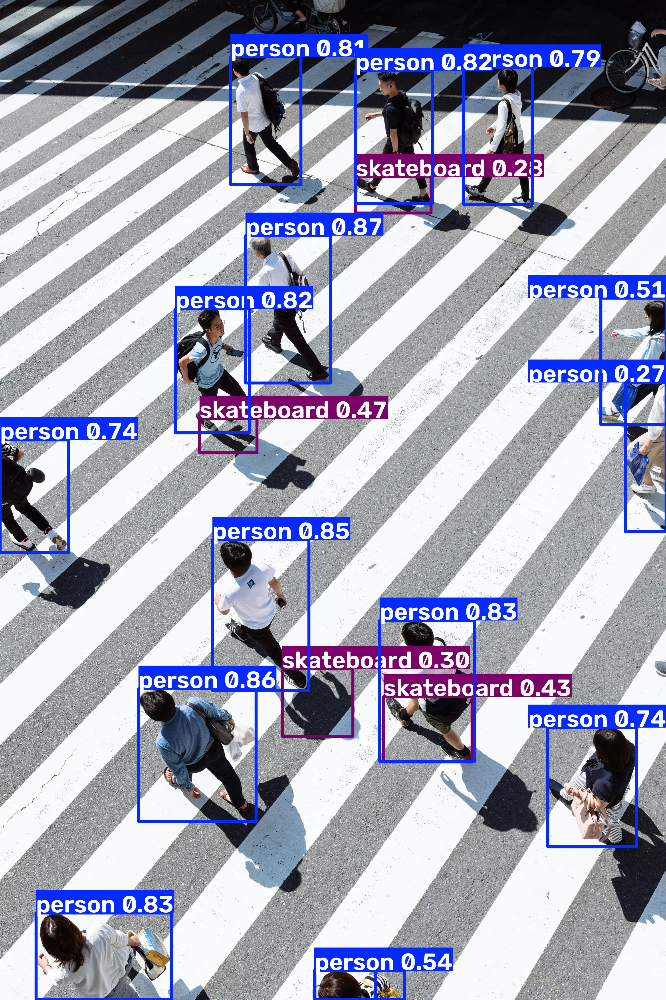

In [67]:
from IPython.display import Image as IPyImage

# IPyImage(filename=f'{HOME}/runs/detect/predict/road1.jpg', width=600)
IPyImage(filename=os.path.join(r"runs/detect/predict/road1.jpg"), width=600)

### SDK

In [68]:
from ultralytics import YOLO
from PIL import Image

model = YOLO('yolo26n.pt')
image = Image.open(f'./road1.jpg')
result = model.predict(image, verbose=False)[0]

**NOTE:** The obtained `result` object stores information about the location, classes, and confidence levels of the detected objects.

The next few cells give a peek into what it contains

In [69]:
result.boxes.xyxy

tensor([[1106.7823, 1059.5642, 1488.6237, 1723.2238],
        [ 624.3823, 3098.5535, 1153.5232, 3696.4062],
        [ 957.4806, 2428.1416, 1391.9092, 3107.8005],
        [ 162.8444, 4108.6152,  773.0254, 4497.8506],
        [1710.9343, 2791.7776, 2138.4680, 3426.6614],
        [1599.9779,  317.9799, 1948.9375,  915.0719],
        [ 790.1225, 1389.9679, 1123.4557, 1946.9399],
        [1038.6735,  255.5562, 1355.6565,  830.3918],
        [2087.4739,  302.5024, 2397.5979,  919.3539],
        [   0.0000, 1979.7136,  309.1217, 2488.0020],
        [2467.5027, 3273.1426, 2867.4573, 3810.6924],
        [1418.6896, 4367.1602, 1821.0255, 4497.8433],
        [2705.0193, 1341.7650, 3000.0000, 1911.0035],
        [ 899.3138, 1883.4468, 1157.5388, 2037.1750],
        [1728.1769, 3135.9250, 2126.0715, 3428.7561],
        [1273.5620, 3008.5078, 1588.3293, 3308.2725],
        [1416.6664, 4366.8174, 1693.0005, 4498.1631],
        [2816.8774, 1719.1514, 3000.0000, 2392.2561],
        [1602.1339,  796.741

In [70]:
result.boxes.conf

tensor([0.8665, 0.8571, 0.8534, 0.8364, 0.8336, 0.8182, 0.8158, 0.8084, 0.7851, 0.7469, 0.7456, 0.5443, 0.5184, 0.4652, 0.4270, 0.3119, 0.2802, 0.2794, 0.2711], device='cuda:0')

In [71]:
result.boxes.cls

tensor([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., 36., 36., 36.,  0.,  0., 36.], device='cuda:0')

**NOTE:** YOLO26 can be easily integrated with `supervision` using the familiar `from_ultralytics` connector. `supervision` is a useful library (by Roboflow) for post-inference processing, visualization, etc.

In [72]:
import supervision as sv

detections = sv.Detections.from_ultralytics(result)

In [73]:
import supervision as sv
from PIL import Image

def annotate(image: Image.Image, detections: sv.Detections) -> Image.Image:
    text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)

    box_annotator = sv.BoxAnnotator()
    label_annotator = sv.LabelAnnotator(
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        smart_position=True
    )

    out = image.copy()
    out = box_annotator.annotate(out, detections)
    out = label_annotator.annotate(out, detections)
    out.thumbnail((1000, 1000))
    return out

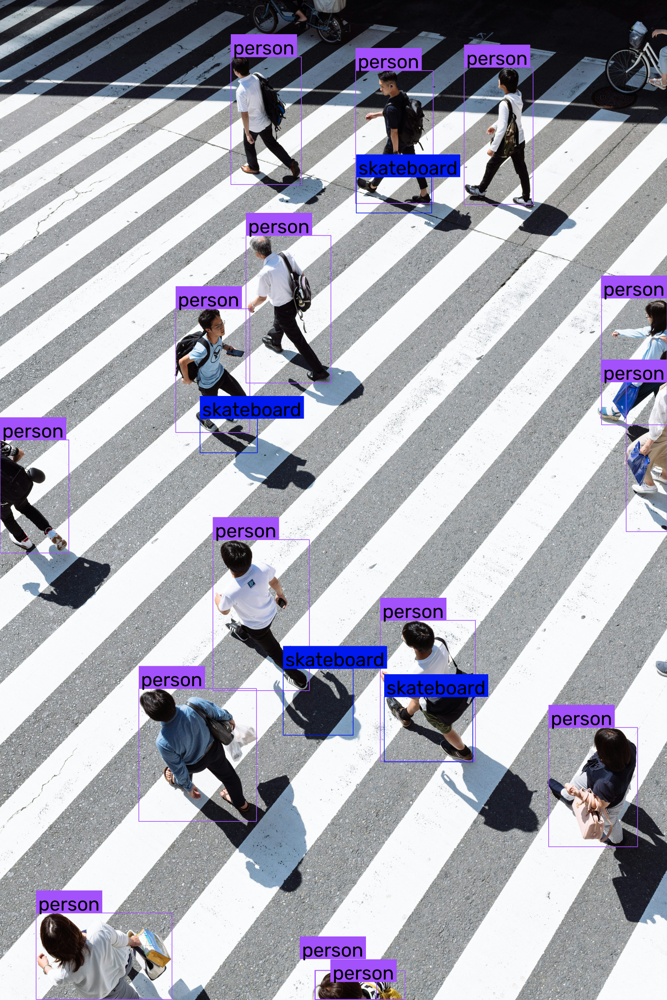

In [74]:
annotated_image = annotate(image, detections)
annotated_image

## Fine-Tuning YOLO26 on PPE Detection Dataset

**NOTE:** make sure your data is located in a directory named
`datasets`.

Running this cell may prompt you asking the following:

> replace /content/datasets/PPEDataset/data.yaml?

Just type `y` if it asks so




In [76]:
# Download the PPEDataset.zip to your colab /content
# Then extract it to /content/datasets/PPEDataset

!mkdir {HOME}/datasets

!unzip -n PPEDataset.zip -d datasets/PPEDataset

# %cd {HOME}/datasets

Archive:  PPEDataset.zip
 extracting: datasets/PPEDataset/test/images/202234-7-_jpg.rf.76126ad26c1fda6bdf4cfa6d94d7bda5.jpg  
 extracting: datasets/PPEDataset/test/images/img17_png_jpg.rf.c4b231d07e3a84b1707728edfb8dc9fb.jpg  
 extracting: datasets/PPEDataset/train/images/20220721_162848_jpg.rf.002f4ae1f6d94f2e897a5cddccd37f88.jpg  
 extracting: datasets/PPEDataset/train/images/image_173_jpg.rf.044fa1db70739c360666857c253a1fa5.jpg  
 extracting: datasets/PPEDataset/train/images/Video4_49_jpg.rf.0b5332039bfec7da4acdc88b075c3055.jpg  
 extracting: datasets/PPEDataset/train/images/Video2_84_jpg.rf.078a0ba9af0b539a9ea6c0c48b3ffb6f.jpg  
 extracting: datasets/PPEDataset/test/images/ppe_0249_jpg.rf.5d44a6dcf2906e102eaf795eacec41cc.jpg  
 extracting: datasets/PPEDataset/test/images/Screenshot-2024-09-24-132620_png.rf.77ad4a1081ccf23ae70dd2a393c48517.jpg  
 extracting: datasets/PPEDataset/train/images/image_242-1-_jpg.rf.0280a597c86245e9bc0d2a3bc42f518b.jpg  
 extracting: datasets/PPEDataset/t

## Train your Customized YOLO26n

Train for atleast 10 epochs

In [77]:
# %cd {HOME}

!yolo task=detect mode=train model=yolo26n.pt data={HOME}/datasets/PPEDataset/data.yaml epochs=10 imgsz=640 plots=True

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/areeb/Documents/KFUPM/COE 512/Ass2/datasets/PPEDataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

**NOTE:** The results of the completed training are saved in `{HOME}/runs/detect/train/`. Let's examine them.

If you run the training code cell multiple times, it will make separate folders for each training session. For example `{HOME}/runs/detect/train-2/`, `{HOME}/runs/detect/train-3/` and so on, so modify the directory paths later on as needed

In [78]:
!ls {HOME}/runs/detect/train/

args.yaml			 confusion_matrix.png  train_batch2.jpg
BoxF1_curve.png			 labels.jpg	       val_batch0_labels.jpg
BoxP_curve.png			 results.csv	       val_batch0_pred.jpg
BoxPR_curve.png			 results.png	       weights
BoxR_curve.png			 train_batch0.jpg
confusion_matrix_normalized.png  train_batch1.jpg


### Confusion Matrix

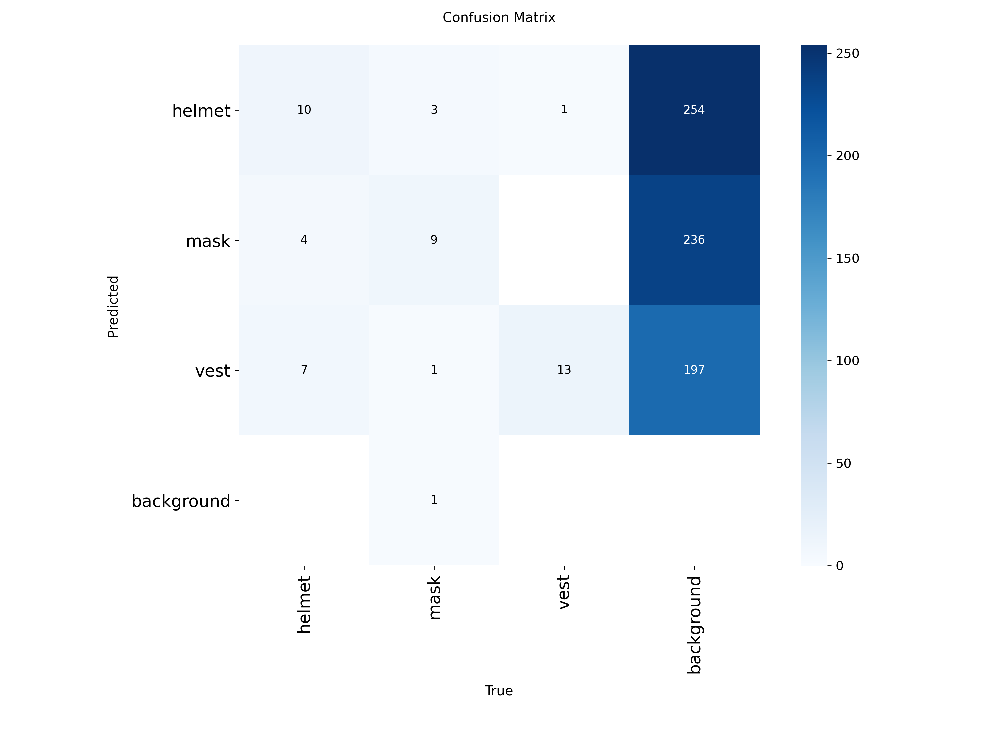

In [79]:
from IPython.display import Image as IPyImage

IPyImage(filename="./runs/detect/train/confusion_matrix.png", width=600)

### Results

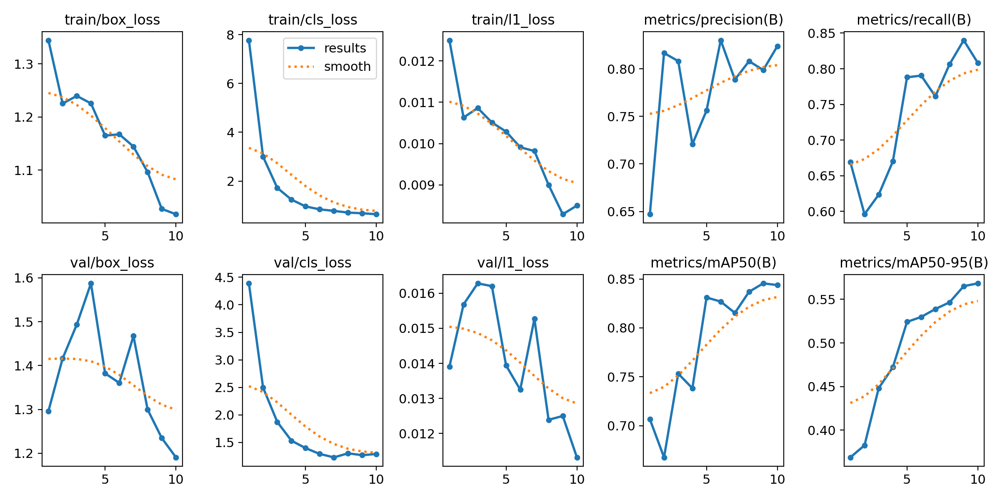

In [80]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'./runs/detect/train/results.png', width=600)

## Validate your Customized YOLO26n

Using the `best.pt` (the best model from training phase), apply the model on the validation set

In [81]:
!yolo task=detect mode=val model=./runs/detect/train/weights/best.pt data=./datasets/PPEDataset/data.yaml

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4206.0±1245.6 MB/s, size: 45.8 KB)
val: Scanning /home/areeb/Documents/KFU…: 100% ━━━━━━━━━━━━ 15/15 7.0Mit/s 0.0s
                 Class     Images  Instanc…: 100% ━━━━━━━━━━━━ 1/1 6.1it/s 0.2s
                   all         15         49      0.824      0.807      0.843      0.568
                helmet         14         21      0.863      0.857      0.964      0.695
                  mask          7         14          1      0.784      0.814      0.515
                  vest          9         14      0.609      0.779      0.751      0.495
Speed: 0.4ms preprocess, 3.1ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /home/areeb/Documents/KFUPM/COE 512/Ass2/runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/

## Inference with your Customized YOLO26n

##### CLI

In [82]:
!yolo task=detect mode=predict model=./runs/detect/train/weights/best.pt source=./datasets/PPEDataset/test/images save=True verbose=False

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
Results saved to /home/areeb/Documents/KFUPM/COE 512/Ass2/runs/detect/predict-2
💡 Learn more at https://docs.ultralytics.com/modes/predict


### SDK

In [83]:
from ultralytics import YOLO

model = YOLO(f'./runs/detect/train/weights/best.pt')

In [84]:
import supervision as sv

ds_test = sv.DetectionDataset.from_yolo(
    images_directory_path=f"./datasets/PPEDataset/test/images",
    annotations_directory_path=f"./datasets/PPEDataset/test/labels",
    data_yaml_path=f"./datasets/PPEDataset/data.yaml"
)

In [85]:
import supervision as sv
from PIL import Image

def annotate(image: Image.Image, detections: sv.Detections) -> Image.Image:
    color = sv.ColorPalette.from_hex([
        "#9999ff", "#3399ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00",
        "#ffff00", "#ff9b00", "#ff8080", "#ff66b2", "#ff66ff", "#b266ff",
    ])

    text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)

    box_annotator = sv.BoxAnnotator(color=color)
    label_annotator = sv.LabelAnnotator(
        color=color,
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        smart_position=True
    )

    out = image.copy()
    out = box_annotator.annotate(out, detections)
    out = label_annotator.annotate(out, detections)
    out.thumbnail((1000, 1000))
    return out

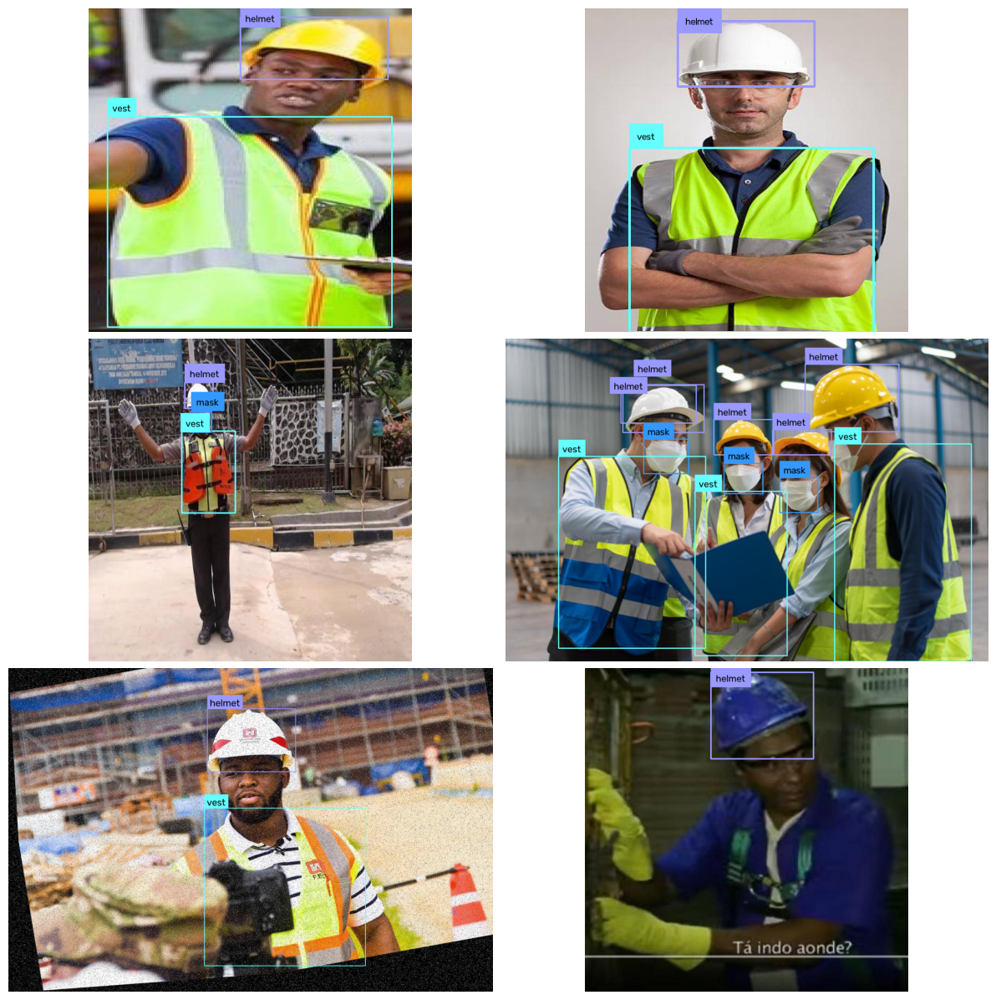

In [88]:
import random
import matplotlib.pyplot as plt

N = 6
L = len(ds_test)

annotated_images = []

for i in random.sample(range(L), N):
    path, _, annotations = ds_test[i]
    image = Image.open(path)
    result = model.predict(image, verbose=False)[0]
    detections = sv.Detections.from_ultralytics(result)
    annotated_image = annotate(image, detections)
    annotated_images.append(annotated_image)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, img in zip(axes.flat, annotated_images):
    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0.02, hspace=0.02, left=0.01, right=0.99, top=0.99, bottom=0.01)

plt.show()

## Exercises

##### Question 1

Train YOLO26n on the PPE Detection Dataset for 20 epochs.

Run the inference of this model on the test set, plot and show the confusion matrix and results (within this jupyter notebook)



In [89]:
# Your code here
# %cd {HOME}

!yolo task=detect mode=train model=yolo26n.pt data={HOME}/datasets/PPEDataset/data.yaml epochs=20 imgsz=640 plots=True

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/areeb/Documents/KFUPM/COE 512/Ass2/datasets/PPEDataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

Confusion Matrix for the 20 epoch model.

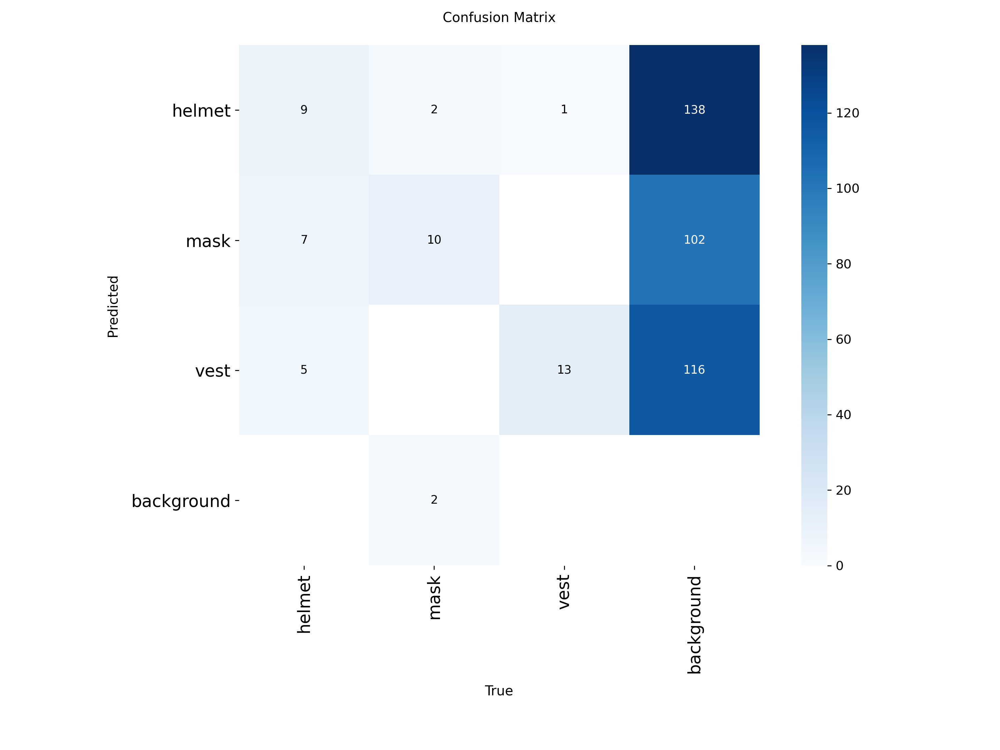

In [90]:
IPyImage(filename="./runs/detect/train-2/confusion_matrix.png", width=600)

Results for the 20 epoch model.

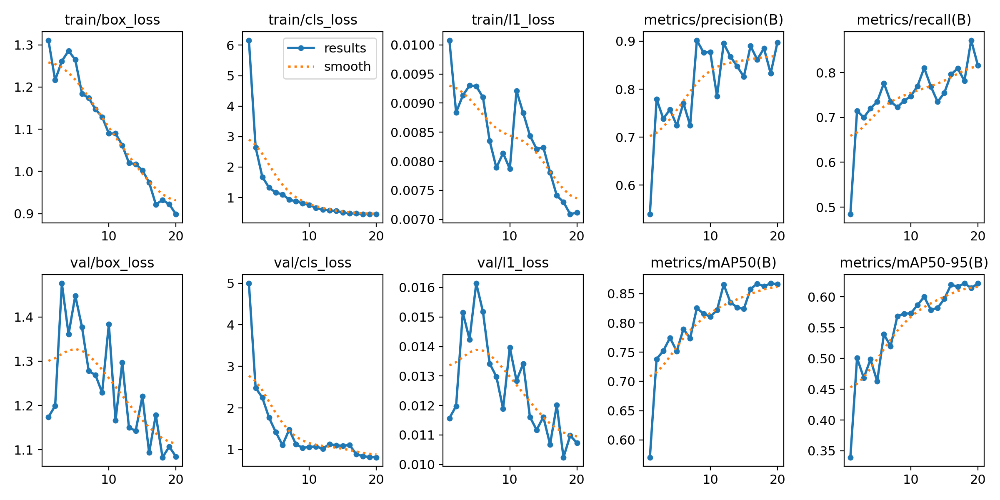

In [93]:
IPyImage(filename=f'./runs/detect/train-2/results.png', width=600)

In [91]:
model_2 = YOLO(f'./runs/detect/train-2/weights/best.pt')

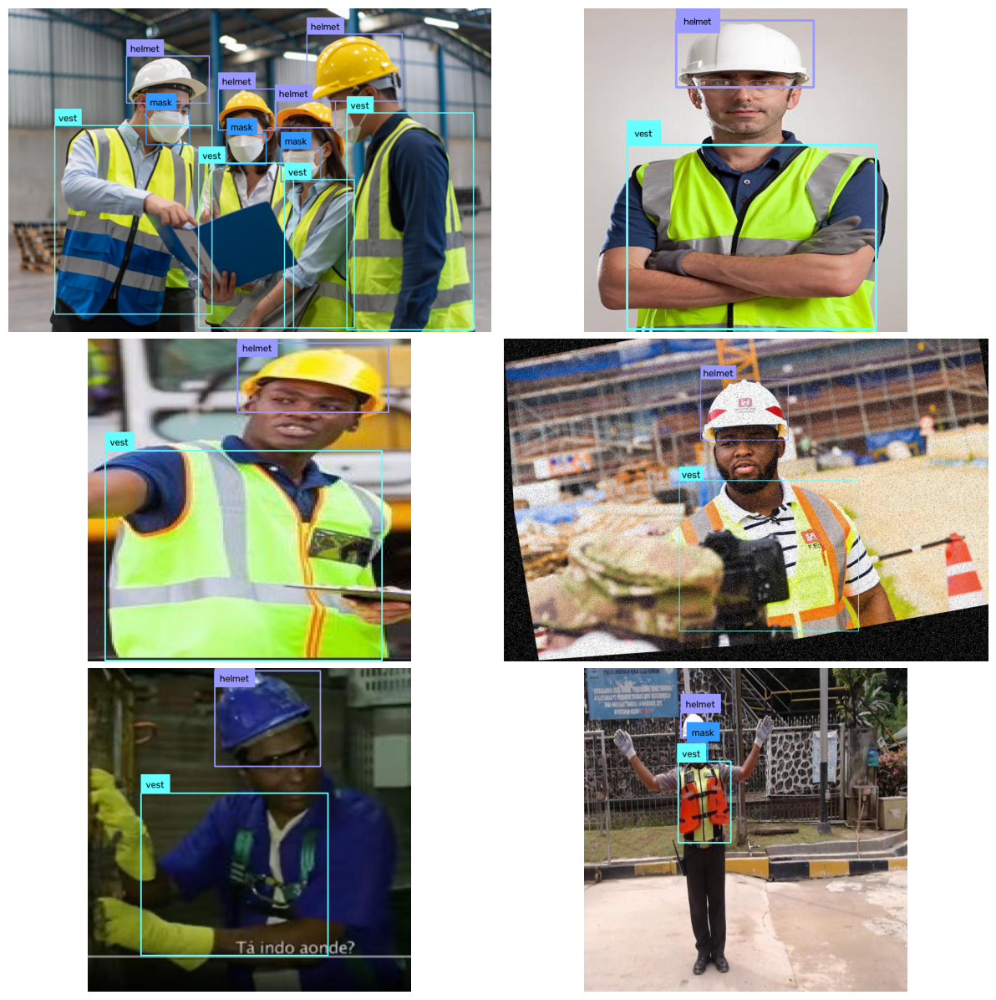

In [92]:
N = 6
L = len(ds_test)

annotated_images = []

for i in random.sample(range(L), N):
    path, _, annotations = ds_test[i]
    image = Image.open(path)
    result = model_2.predict(image, verbose=False)[0]
    detections = sv.Detections.from_ultralytics(result)
    annotated_image = annotate(image, detections)
    annotated_images.append(annotated_image)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, img in zip(axes.flat, annotated_images):
    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0.02, hspace=0.02, left=0.01, right=0.99, top=0.99, bottom=0.01)

plt.show()

##### Question 2

Compare the results of the first YOLO26n you trained for 10 epochs against the results of the second YOLO26n you trained for 20 epochs.
Comment on the confusion matrix and performance.

`Your answers here`